Imports and paths

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.offsetbox import TextArea, HPacker, AnchoredOffsetbox

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"
processed_data_dir = ROOT / "data" / "processed"
reports_figures = ROOT / "reports" / "figures"

Loading the data

In [3]:
competitions = pd.read_csv(raw_data_dir / "competitions.csv.gz")
clubs = pd.read_csv(raw_data_dir / "clubs.csv.gz")
valuations = pd.read_csv(raw_data_dir / "player_valuations.csv.gz")
players = pd.read_csv(raw_data_dir / "players.csv.gz")
appearances = pd.read_csv(raw_data_dir / "appearances.csv.gz")

# One row per Premier League 2025-26 player with a value at both dates, built by src/make_dataset.py
pl_players_2025_26 = pd.read_csv(processed_data_dir / "pl_players_2025_26.csv")

The Premier League clubs of the 2025-26 season

In [4]:
pl_clubs = clubs[(clubs["domestic_competition_id"] == "GB1") & (clubs["last_season"] == 2025)]
display(pl_clubs)
print(f"Number of Premier League clubs: {len(pl_clubs['name'])}")

,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,filename,url
50,11,fc-arsenal,Arsenal FC,GB1,NaN,29,26.2,19,65.5,21,Emirates Stadium,60704,€-20.00m,Mikel Arteta,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-arsenal/sta...
67,1132,fc-burnley,Burnley FC,GB1,NaN,30,25.9,24,80.0,12,Turf Moor,21994,€-6.50m,Scott Parker,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-burnley/sta...
72,1148,fc-brentford,Brentford FC,GB1,NaN,34,25.0,25,73.5,16,Gtech Community Stadium,17250,€-28.50m,Keith Andrews,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-brentford/s...
97,1237,brighton-amp-hove-albion,Brighton & Hove Albion,GB1,NaN,37,25.0,29,78.4,19,AMEX Stadium,31876,€-8.70m,Fabian Hürzeler,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/brighton-amp-h...
154,148,tottenham-hotspur,Tottenham Hotspur,GB1,NaN,37,25.5,28,75.7,24,Tottenham Hotspur Stadium,62850,€-251.20m,Thomas Frank,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/tottenham-hots...
333,281,manchester-city,Manchester City,GB1,NaN,32,25.2,20,62.5,22,Etihad Stadium,61000,€-152.03m,Pep Guardiola,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/manchester-cit...
343,289,afc-sunderland,Sunderland AFC,GB1,NaN,31,25.7,25,80.6,16,Stadium of Light,48707,+€22.00m,Régis Le Bris,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/afc-sunderland...
345,29,fc-everton,Everton FC,GB1,NaN,23,25.8,11,47.8,9,Hill Dickinson Stadium,52769,€-65.30m,David Moyes,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-everton/sta...
368,31,fc-liverpool,Liverpool FC,GB1,NaN,29,25.4,22,75.9,18,Anfield,61276,€-103.60m,Arne Slot,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/fc-liverpool/s...
447,379,west-ham-united,West Ham United,GB1,NaN,27,25.8,17,63.0,11,London Stadium,62500,+€97.85m,Graham Potter,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/west-ham-unite...


Number of Premier League clubs: 20


Let’s go and look at Arsenal’s squad, the PL champions of the 2025-26 season.

In [5]:
TEAM_FILTER = "Arsenal FC"

arsenal_players = players[
    players["current_club_id"].isin(pl_clubs[pl_clubs["name"] == TEAM_FILTER]["club_id"])
    & (players["last_season"] == 2025)
]

arsenal_players[
    ["first_name", "last_name", "position", "market_value_in_eur"]
].sort_values("position", key=lambda x: x.map({"Goalkeeper": 0, "Defender": 1, "Midfield": 2, "Attack": 3}))

,first_name,last_name,position,market_value_in_eur
45898,Jack,Porter,Goalkeeper,300000.0
12889,Kepa,Arrizabalaga,Goalkeeper,5000000.0
16803,David,Raya,Goalkeeper,30000000.0
45102,Khari,Ranson,Goalkeeper,NaN
41335,Alexéi,Rojas,Goalkeeper,250000.0
38762,Tommy,Setford,Goalkeeper,500000.0
27847,Riccardo,Calafiori,Defender,55000000.0
43071,Jaden,Dixon,Defender,NaN
41927,Josh,Nichols,Defender,NaN
39767,Myles,Lewis-Skelly,Defender,45000000.0


Market value of each Arsenal player

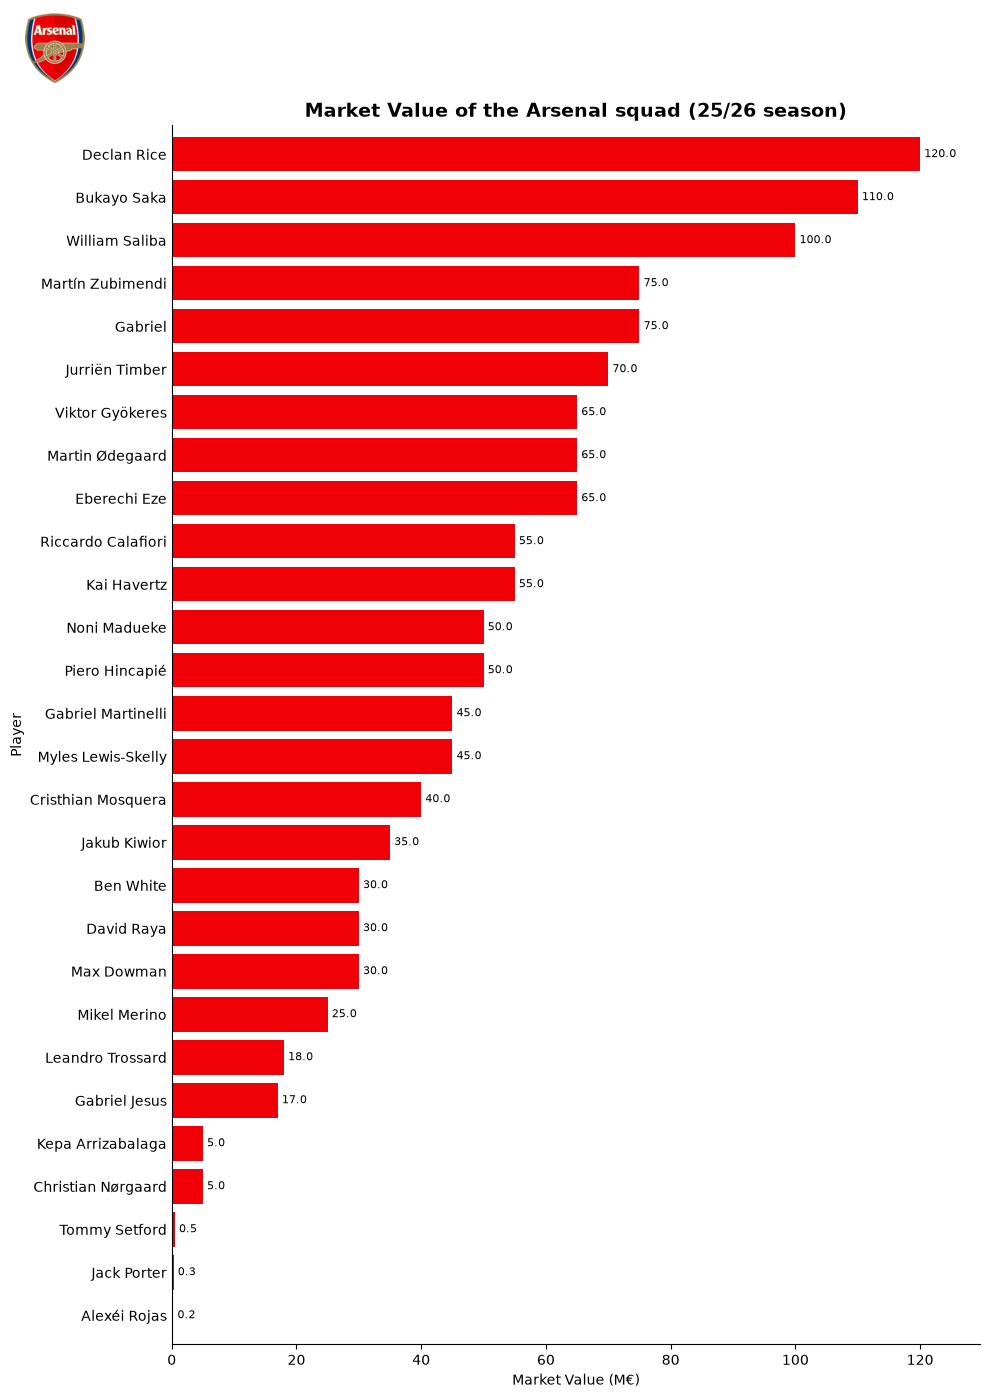

In [6]:
ARSENAL_ID = 11
LAST_SEASON = 2025

a = players[
    (players["current_club_id"] == ARSENAL_ID)
    & (players["last_season"] == LAST_SEASON)
].dropna(subset=["market_value_in_eur"])

a = a.sort_values("market_value_in_eur", ascending=True)

fig, ax = plt.subplots(figsize=(10, 14))
values = a["market_value_in_eur"] / 1e6
bars = ax.barh(a["name"], values, color="#EF0107")
ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=3, fontsize=8)
ax.set_xlabel("Market Value (M€)")
ax.set_ylabel("Player")
ax.set_title("Market Value of the Arsenal squad (25/26 season)", fontsize=14, fontweight="bold")
ax.margins(x=0.08, y=0.01)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout(rect=[0, 0, 1, 0.94])

logo_ax = fig.add_axes([0.02, 0.94, 0.08, 0.055])
arsenal_logo = f"{ARSENAL_ID}.png"
logo_ax.imshow(plt.imread(ROOT / "assets" / "clubs_logo" / arsenal_logo))
logo_ax.axis("off")

plt.savefig(reports_figures / "arsenal_squad_market_value.png", dpi=150)
plt.show()

We can also look at the squad composition by position for each team

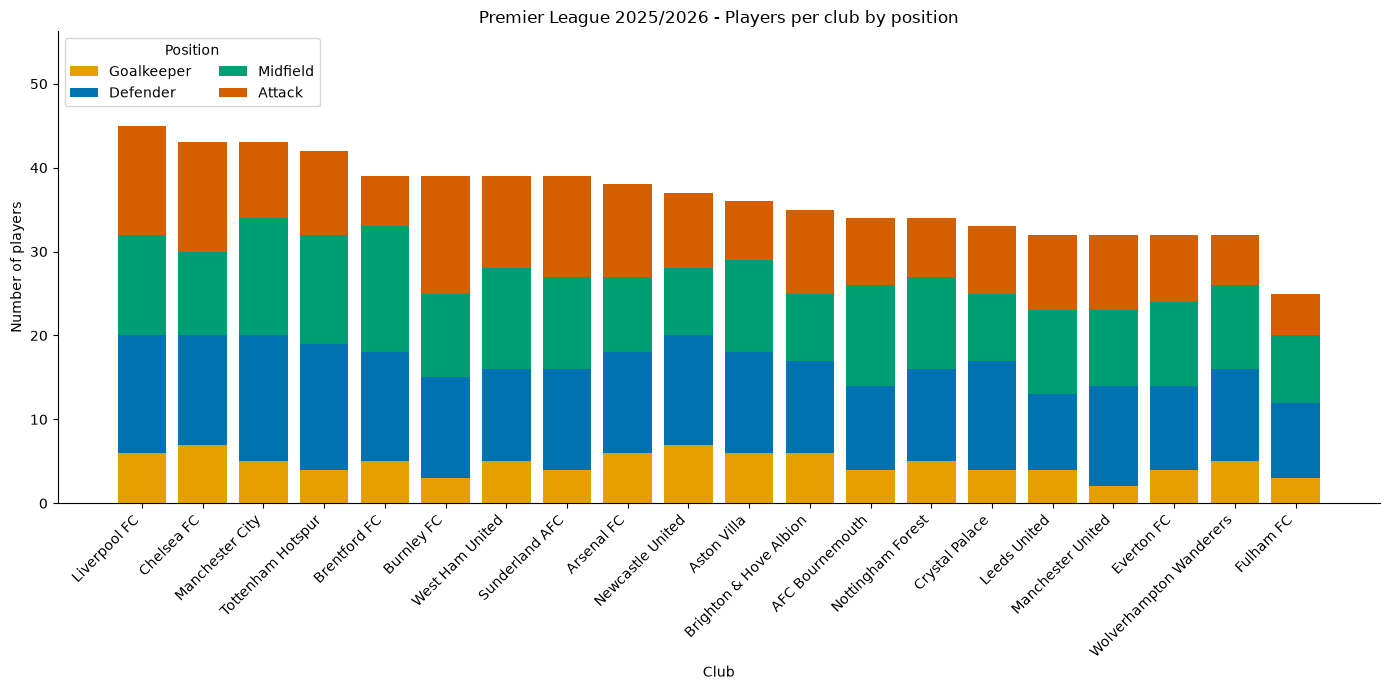

In [7]:
positions = ["Goalkeeper", "Defender", "Midfield", "Attack"]
colors = {"Goalkeeper": "#E69F00", "Defender": "#0072B2", "Midfield": "#009E73", "Attack": "#D55E00"}

pl_players = players[
    players["current_club_id"].isin(pl_clubs["club_id"]) & (players["last_season"] == 2025)
].merge(pl_clubs[["club_id", "name"]].rename(columns={"name": "club"}), left_on="current_club_id", right_on="club_id")

counts = (
    pl_players.groupby(["club", "position"]).size().unstack(fill_value=0)
    .reindex(columns=positions, fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 7))
bottom = pd.Series(0, index=counts.index)
for pos in positions:
    ax.bar(counts.index, counts[pos], bottom=bottom, color=colors[pos], label=pos)
    bottom += counts[pos]

ax.set_xlabel("Club")
ax.set_ylabel("Number of players")
ax.set_title("Premier League 2025/2026 - Players per club by position")
ax.set_ylim(0, bottom.max() * 1.25)
ax.legend(loc="upper left", title="Position", ncol=2)
plt.xticks(rotation=45, ha="right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "players_per_club_by_position.png", dpi=150)
plt.show()

The top 5 players by market value for each team

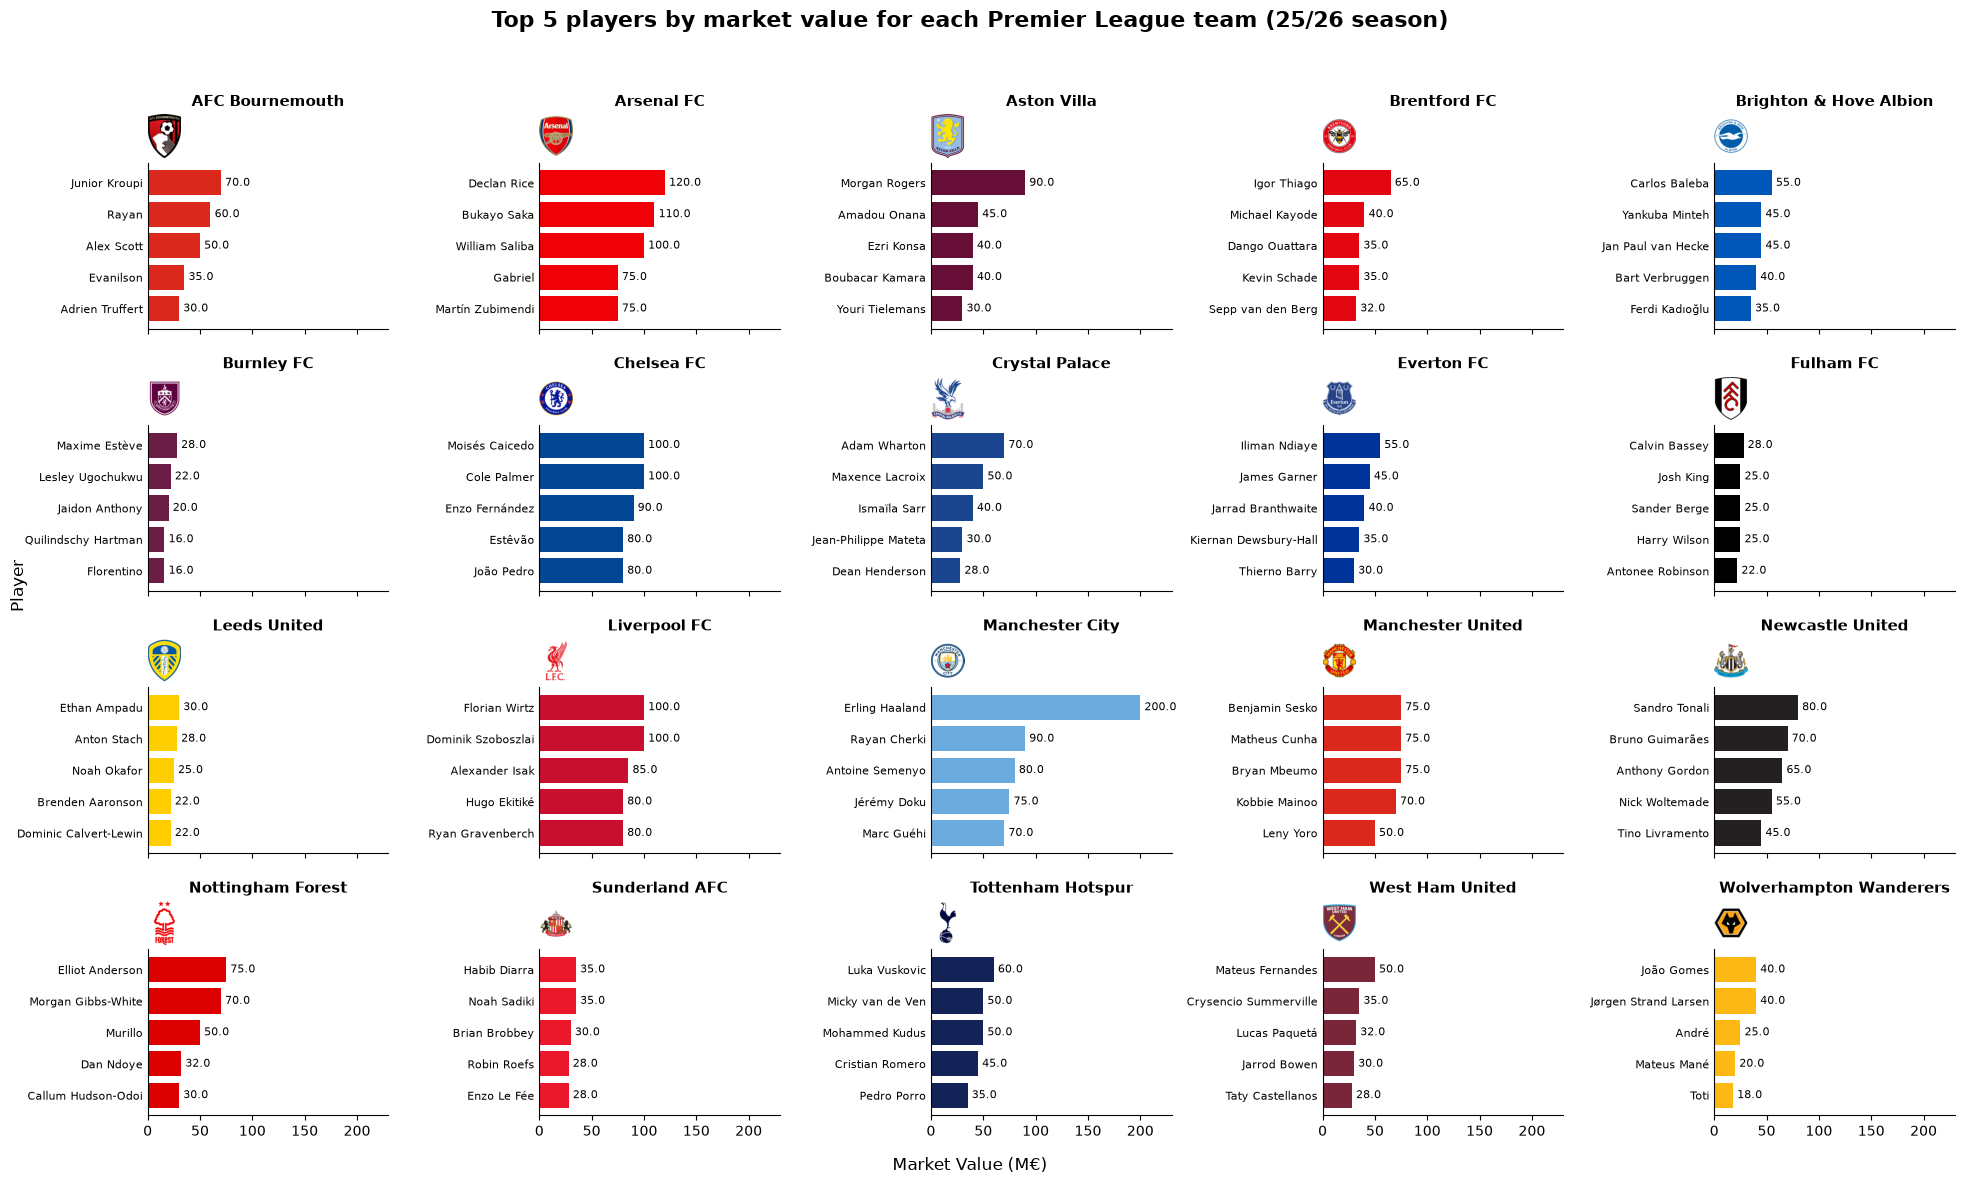

In [8]:
CLUB_COLORS = {
    11: "#EF0107",    # Arsenal
    1132: "#6C1D45",  # Burnley
    1148: "#E30613",  # Brentford 
    1237: "#0057B8",  # Brighton
    148: "#132257",   # Tottenham
    281: "#6CABDD",   # Manchester City
    289: "#EB172B",   # Sunderland 
    29: "#003399",    # Everton
    31: "#C8102E",    # Liverpool
    379: "#7A263A",   # West Ham
    399: "#FFCD00",   # Leeds
    405: "#670E36",   # Aston Villa
    543: "#FDB913",   # Wolves
    631: "#034694",   # Chelsea
    703: "#DD0000",   # Nottingham Forest
    762: "#241F20",   # Newcastle
    873: "#1B458F",   # Crystal Palace
    931: "#000000",   # Fulham
    985: "#DA291C",   # Manchester United
    989: "#DA291C",   # Bournemouth
}

pl_players = players[
    (players["current_club_id"].isin(pl_clubs["club_id"]))
    & (players["last_season"] == 2025)
].dropna(subset=["market_value_in_eur"])

top5 = pl_players.groupby("current_club_id").apply(
    lambda x: x.nlargest(5, "market_value_in_eur"), include_groups=False
).reset_index(level=0)

fig, axes = plt.subplots(4, 5, figsize=(20,12), sharex=True)
for ax, (_, club) in zip(axes.flat, pl_clubs.sort_values("name").iterrows()) :
    logo = plt.imread(ROOT / "assets" / "clubs_logo" / f"{club['club_id']}.png")
    t = top5[top5["current_club_id"] == club["club_id"]].sort_values("market_value_in_eur")
    values = t["market_value_in_eur"] / 1e6
    bars = ax.barh(t["name"], values, color = CLUB_COLORS[club["club_id"]])
    ax.bar_label(bars, labels=[f"{v}" for v in values], padding = 3, fontsize = 8)
    ax.set_title(club["name"], fontsize=11, fontweight="bold")
    ax.margins(x=0.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=8)

    logo_ax = ax.inset_axes([0, 1.02, 0.14, 0.28])
    logo_ax.imshow(logo)
    logo_ax.axis("off")

fig.suptitle("Top 5 players by market value for each Premier League team (25/26 season)", fontsize=16, fontweight="bold")
fig.supxlabel("Market Value (M€)")
fig.supylabel("Player")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(reports_figures / "top5_players_per_team.png", dpi=150)
plt.show()

How did the market value of each team's top 5 players change during the 2025-26 season? The top 5 is chosen at the end of the season, and we compare their value at the start and at the end of the season.

In [9]:
def get_valuations(name):
    player_id = int(players.loc[players["name"].eq(name), "player_id"].iloc[0])
    player_valuations = valuations[valuations["player_id"] == player_id]
    return player_valuations.sort_values(["date"])[2 * len(player_valuations) // 3:]

get_valuations("Bruno Fernandes")

,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id
381101,240306,2021-03-18,90000000,Manchester United,985,GB1
388681,240306,2021-06-01,90000000,Manchester United,985,GB1
419393,240306,2021-12-23,90000000,Manchester United,985,GB1
450054,240306,2022-06-15,85000000,Manchester United,985,GB1
469473,240306,2022-11-03,75000000,Manchester United,985,GB1
507094,240306,2023-06-20,75000000,Manchester United,985,GB1
536171,240306,2023-12-19,70000000,Manchester United,985,GB1
551957,240306,2024-05-27,70000000,Manchester United,985,GB1
571169,240306,2024-10-01,65000000,Manchester United,985,GB1
582103,240306,2024-12-16,55000000,Manchester United,985,GB1


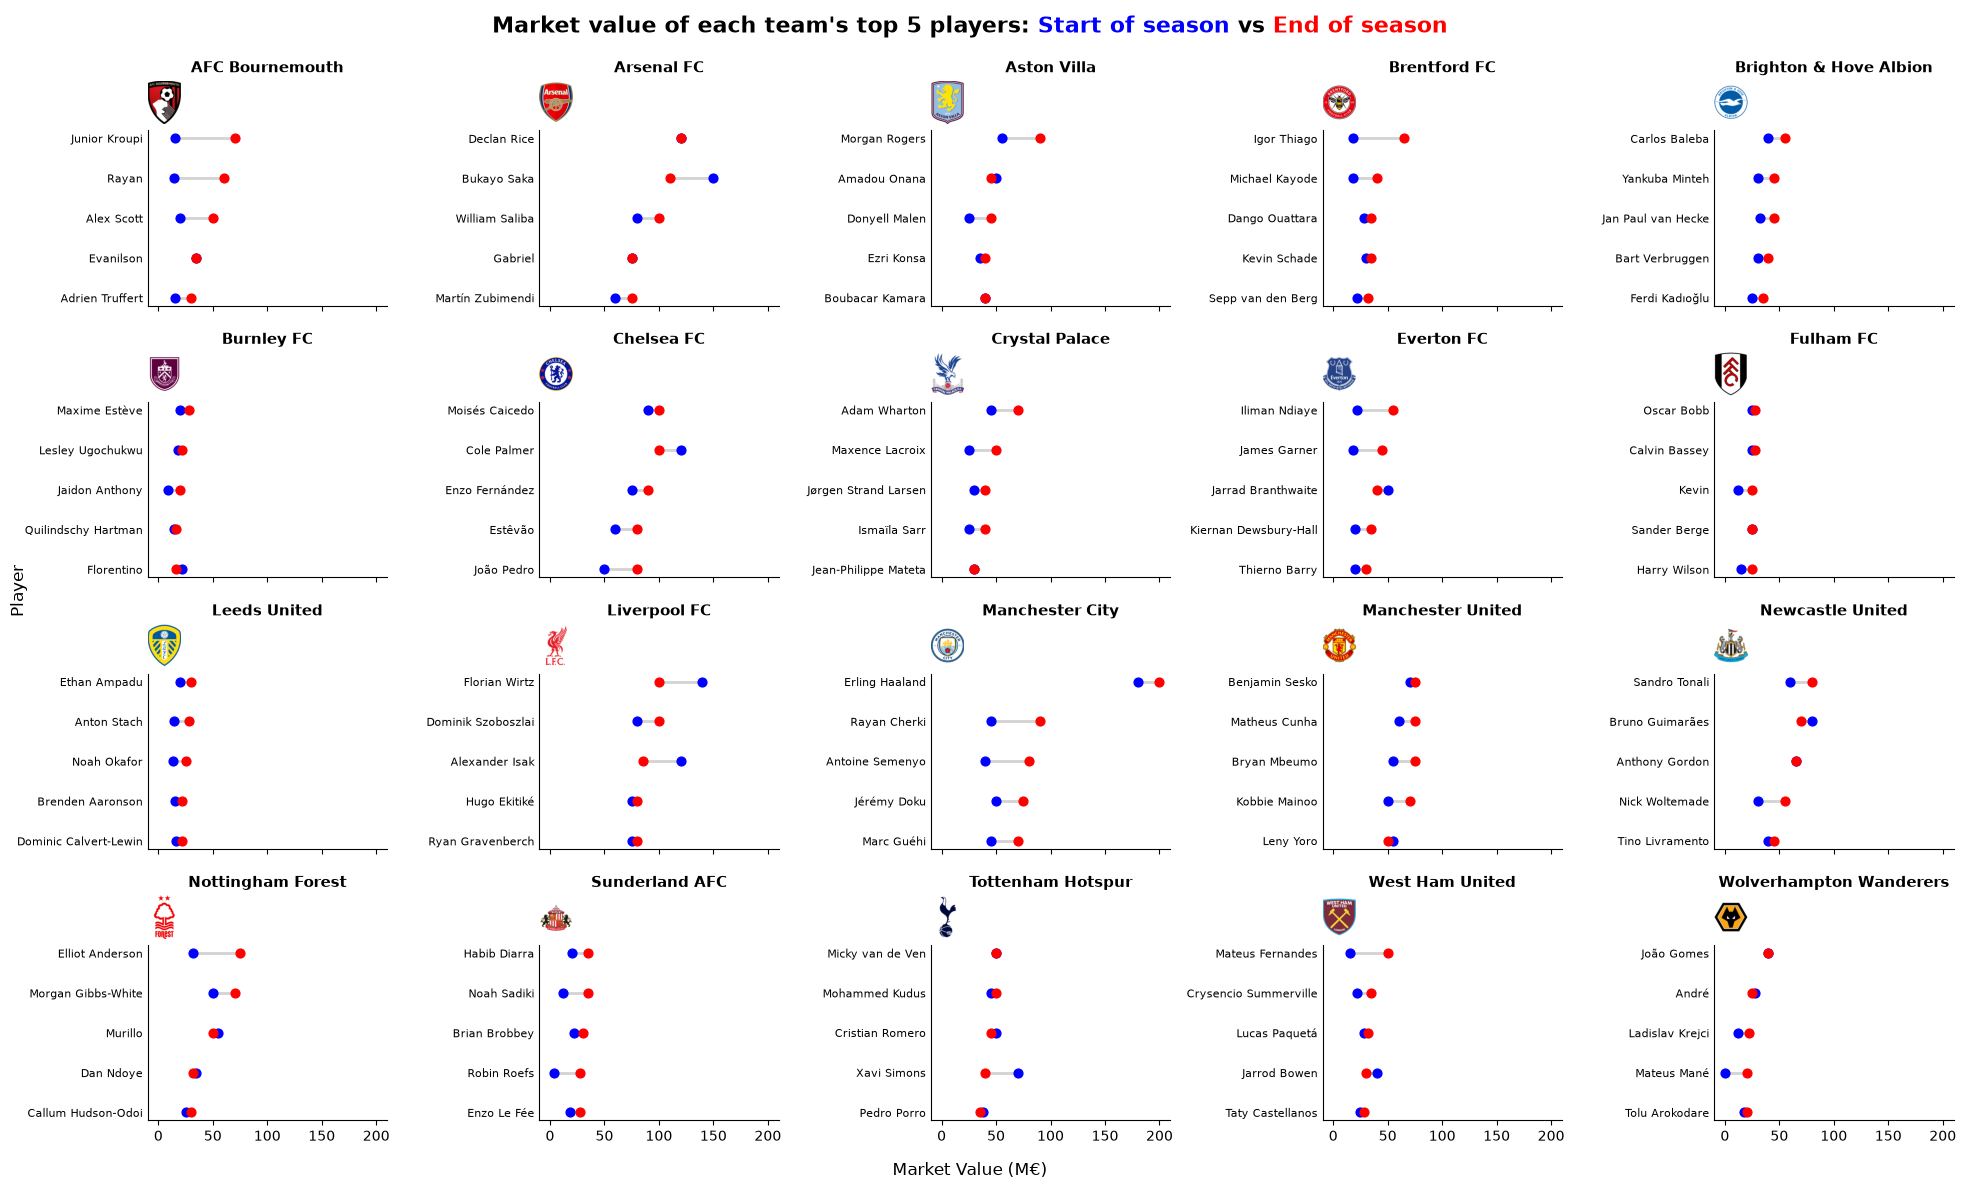

In [10]:
date_1 = "2025-08-15"
date_2 = "2026-06-03"
COLOR_1 = "blue"
COLOR_2 = "red"

pl_players = pl_players_2025_26.rename(
    columns={"club_id": "current_club_id", "value_start_eur": "value_1", "value_end_eur": "value_2"}
)

top5 = pl_players.groupby("current_club_id").apply(
    lambda g: g.nlargest(5, "value_2"), include_groups=False
).reset_index(level=0)

fig, axes = plt.subplots(4, 5, figsize=(20, 12), sharex=True)
for ax, (_, club) in zip(axes.flat, pl_clubs.sort_values("name").iterrows()):
    logo = plt.imread(ROOT / "assets" / "clubs_logo" / f"{club['club_id']}.png")
    t = top5[top5["current_club_id"] == club["club_id"]].sort_values("value_2")
    ax.hlines(t["name"], t["value_1"] / 1e6, t["value_2"] / 1e6, color="lightgrey", linewidth=2)
    ax.scatter(t["value_1"] / 1e6, t["name"], color=COLOR_1, s=40, label=date_1, zorder=3)
    ax.scatter(t["value_2"] / 1e6, t["name"], color=COLOR_2, s=40, label=date_2, zorder=3)
    ax.set_title(club["name"], fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=8)

    logo_ax = ax.inset_axes([0, 1.02, 0.14, 0.28])
    logo_ax.imshow(logo)
    logo_ax.axis("off")

parts = [
    ("Market value of each team's top 5 players: ", "black"),
    ("Start of season", COLOR_1),
    (" vs ", "black"),
    ("End of season", COLOR_2),
]
boxes = [TextArea(text, textprops=dict(color=c, fontsize=16, fontweight="bold")) for text, c in parts]
title = AnchoredOffsetbox(
    loc="upper center", child=HPacker(children=boxes, pad=0, sep=0),
    bbox_to_anchor=(0.5, 0.99), bbox_transform=fig.transFigure, frameon=False,
)
fig.add_artist(title)
fig.supxlabel("Market Value (M€)")
fig.supylabel("Player")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(reports_figures / "top5_value_evolution.png", dpi=150)
plt.show()

Let’s find the top 5 goal scorers and the top 5 assist providers of the 2025-26 Premier League season, so we can see their impact on the market value between the start and the end of the season.

In [11]:
# Value change in M€ between date_1 and date_2, for each player of the processed dataset
value_change = (pl_players_2025_26.set_index("player_id")["value_change_eur"] / 1e6).astype(int)

In [12]:
stats = pl_players_2025_26[["player_id", "name", "goals", "assists"]].rename(columns={"name": "player_name"})

top5_goals = stats.nlargest(5, "goals")

top5_assists = stats.nlargest(5, "assists")

top5_goals.index = top5_assists.index = [1, 2, 3, 4, 5]

The top 5 goal scorers

In [13]:
top5_goals

,player_id,player_name,goals,assists
1,418560,Erling Haaland,27,8
2,739443,Igor Thiago,22,1
3,583255,Antoine Semenyo,17,4
4,324358,Ollie Watkins,16,3
5,429014,Morgan Gibbs-White,15,4


The top 5 assist providers

In [14]:
top5_assists

,player_id,player_name,goals,assists
1,240306,Bruno Fernandes,9,21
2,607223,Rayan Cherki,4,12
3,314875,Jarrod Bowen,9,11
4,418560,Erling Haaland,27,8
5,626724,João Pedro,15,8


**Note:** the assists come from Transfermarkt, which counts them more broadly than the official Premier League (for example a pass leading to a penalty or a rebound). The numbers can be higher than on the PL website: João Pedro has 8 assists here and 5 on premierleague.com. The goals match the official numbers, but the assists ranking may differ.

Market value change (in M€) for the top 5 goal scorers and the top 5 assist providers

In [15]:
top5_goals["value_change_m_eur"] = top5_goals["player_id"].map(value_change)
top5_assists["value_change_m_eur"] = top5_assists["player_id"].map(value_change)

print("TOP 5 GOALS")
display(top5_goals.style.format({"value_change_m_eur": "{:+.0f}"}))

print("TOP 5 ASSISTS")
display(top5_assists.style.format({"value_change_m_eur": "{:+.0f}"}))

TOP 5 GOALS


,player_id,player_name,goals,assists,value_change_m_eur
1,418560,Erling Haaland,27,8,+20
2,739443,Igor Thiago,22,1,+47
3,583255,Antoine Semenyo,17,4,+40
4,324358,Ollie Watkins,16,3,-15
5,429014,Morgan Gibbs-White,15,4,+20


TOP 5 ASSISTS


,player_id,player_name,goals,assists,value_change_m_eur
1,240306,Bruno Fernandes,9,21,-15
2,607223,Rayan Cherki,4,12,+45
3,314875,Jarrod Bowen,9,11,-10
4,418560,Erling Haaland,27,8,+20
5,626724,João Pedro,15,8,+30


Here we can see that for the top 5 goal scorers : 4/5 players increased their market value, and for the top 5 assist providers : 3/5 players increased their market value. 

A player's market value does not depend only on goals and assists : age, remaining contract length, and other factors also play a role. A top performer can therefore lose value, just like Bruno Fernandes

## Conclusion

- During the 2025-26 season, the market value of most of the top 5 players of each team went up.
- 4 of the top 5 goal scorers and 3 of the top 5 assist providers gained value.
- Goals and assists are not enough to explain the value: a top performer like Bruno Fernandes can lose value. The other factors (age, contract, playing time...) are studied in the combined analysis notebook.